# ETH 市场状态分类：预测未来 30 天是震荡市还是单边市

**研究目标**：用机器学习分类模型，在**当前时刻 t** 仅凭历史信息（t 及以前的数据）预测**未来 30 天窗口 [t+1, t+30]** 是「震荡市」还是「单边市」。

- 数据来源：Binance 日频 OHLCV，缓存于 `data/eth_usdt_1d.csv`（2021-01-01 ~ 2025-12-31，共 1826 根日线）
- 标签定义：未来窗口的「趋势强度 = |累计对数收益| / 年化波动率」，超过分位数阈值判为单边市（trend），否则为震荡市（range）
- 建模流程：特征仅用 t 时刻及以前信息（严格防泄漏）→ XGBoost / 逻辑回归 → **扩张窗口 walk-forward** 滚动验证

由于类别不平衡，accuracy 会失真，故以 **AUC / PR-AUC** 及最优阈值下的精确率-召回率为主要指标，重点关注对「单边市」的召回率（网格策略最需要在单边来临前停机）

## 1. 环境与全局参数

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    confusion_matrix,
)
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# ---- 路径约定 ----
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "eth_usdt_1d.csv"

# ---- 全局可调参数 ----
H = 30                 # 预测窗口：未来 H 天
SCORE_QUANTILE = 0.60  # 趋势强度阈值分位数（60% 分位以下判震荡，以上判单边）
N_FOLDS = 4            # 时间切分数（训练为扩张窗口，产生 N_FOLDS-2 个测试折）
RANDOM_STATE = 42

# ---- 绘图风格 ----
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "Noto Sans CJK SC",
    "axes.unicode_minus": False,
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

assert DATA_PATH.exists(), f"数据文件不存在: {DATA_PATH}"
print("参数就绪，数据路径:", DATA_PATH)

参数就绪，数据路径: /home/nullwinters/Projects/CryptoGrid/data/eth_usdt_1d.csv


## 2. 数据加载与校验

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

print(f"行数: {len(df)}")
print(f"时间范围: {df['timestamp'].min():%Y-%m-%d} ~ {df['timestamp'].max():%Y-%m-%d}")
print(f"缺失值总数: {int(df.isna().sum().sum())}")

df["logret"] = np.log(df["close"]).diff()
print(f"对数收益率缺失(首行): {int(df['logret'].isna().sum())}")
df.head(3)

行数: 1826
时间范围: 2021-01-01 ~ 2025-12-31
缺失值总数: 0
对数收益率缺失(首行): 1


,timestamp,open,high,low,close,volume,logret
0,2021-01-01,737.61,749.11,715.62,728.52,3084.37850,NaN
1,2021-01-02,729.46,787.22,715.34,774.56,8325.47357,0.061280
2,2021-01-03,774.60,1010.82,768.74,978.14,19330.21676,0.233358


## 3. 标签构造（未来 30 天：震荡 vs 单边）

### 3.1 定义

对每个交易日 t，取**未来窗口** `[t+1, t+30]`，计算：

- 累计对数收益：`fut_logret = Σ_{i=1..H} logret[t+i]`
- 年化波动率：`fut_vol = std(logret[t+1..t+H]) × √365`
- 趋势强度：`trend_score = |fut_logret| / fut_vol`

**直觉**：若未来窗口内价格走出一段与波动率相比「足够大且方向一致」的行情，即为单边市；若收益被波动淹没（来回震荡），则为震荡市。

### 3.2 阈值选择

直接用固定阈值（如 0.3）会因行情差异而失衡，这里采用**训练期全样本趋势强度的分位数** `SCORE_QUANTILE=0.60`：即历史上约 40% 的时间段属于「单边市」。该阈值在 walk-forward 中**固定不变**（用全量历史分位确定，避免每折重新标定引入差异）。

> ⚠️ **防泄漏关键**：`shift(-H)` 保证标签只依赖 t 之后的数据，特征只依赖 t 及以前的数据；两者对齐后，训练/测试严格按时间切分。

In [3]:
H = 30
fut_logret = df["logret"].shift(-H).rolling(H).sum()
fut_vol = df["logret"].shift(-H).rolling(H).std() * np.sqrt(365)
trend_score = fut_logret.abs() / fut_vol

print("趋势强度描述统计:")
print(trend_score.dropna().describe().round(4))

thr = trend_score.dropna().quantile(SCORE_QUANTILE)
labels = (trend_score >= thr).astype(int)

print(f"\n阈值(第 {SCORE_QUANTILE:.0%} 分位) = {thr:.4f}")
vc = labels.value_counts().sort_index()
for k, v in vc.items():
    print(f"  {'单边' if k else '震荡'}: {v} 天 ({v/len(labels):.1%})")

趋势强度描述统计:
count    1767.0000
mean        0.2372
std         0.1898
min         0.0001
25%         0.0892
50%         0.1942
75%         0.3428
max         1.1769
Name: logret, dtype: float64

阈值(第 60% 分位) = 0.2516
  震荡: 1119 天 (61.3%)
  单边: 707 天 (38.7%)


### 3.3 标签可视化

将真实 regime 按时间着色：红色=单边市，灰色=震荡市。可直观看到市场在「趋势段」与「震荡段」之间切换——这正是本模型要提前预测的对象。

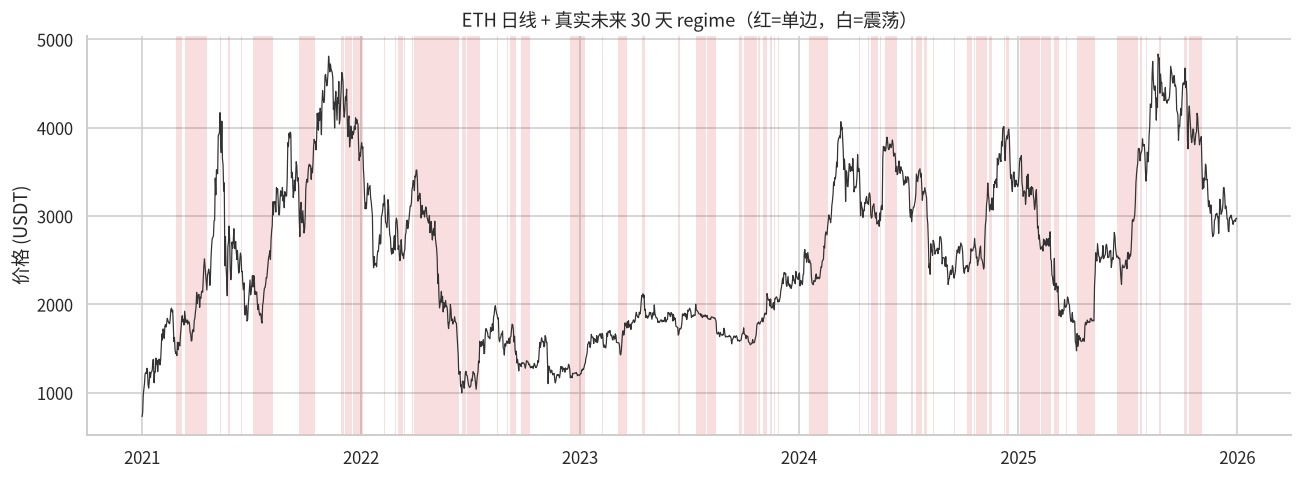

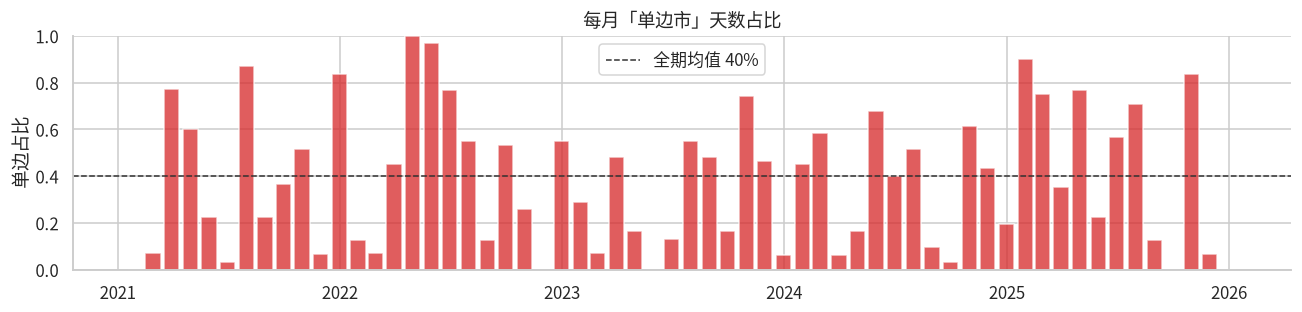

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(df["timestamp"], df["close"], lw=0.8, color="#333333", zorder=3)
for ts, lab in zip(df["timestamp"], labels):
    if lab == 1:
        ax.axvspan(ts, ts + pd.Timedelta(days=1), color="#d62728", alpha=0.15, linewidth=0)
ax.set_title(f"ETH 日线 + 真实未来 30 天 regime（红=单边，白=震荡）")
ax.set_ylabel("价格 (USDT)")
plt.tight_layout()
plt.show()

# 时间轴上单边占比的月度统计，观察 regime 的持续性
tmp = pd.DataFrame({"ts": df["timestamp"], "lab": labels})
monthly = tmp.set_index("ts").resample("ME").mean()
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(monthly.index, monthly["lab"], width=25, color="#d62728", alpha=0.75)
ax.axhline(1 - SCORE_QUANTILE, color="#333", ls="--", lw=1, label=f"全期均值 {1-SCORE_QUANTILE:.0%}")
ax.set_title("每月「单边市」天数占比")
ax.set_ylabel("单边占比")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

## 4. 特征工程（仅用 t 时刻及以前信息）

借鉴 Kaggle 市场制度分类 notebook 与 `XGBoostData` 项目的特征体系，适配日频数据。**所有特征都用 `rolling` 窗口在 t 及以前的历史上计算，不触碰未来。**

| 类别 | 特征 | 计算方式 |
|---|---|---|
| 动量 | `ret5 / ret10 / ret20 / ret60` | 5/10/20/60 日简单收益率 |
| 动量 | `slope20` | 最近 20 日收盘价线性回归斜率 / 收盘价（归一化） |
| 波动 | `vol20 / vol60` | 20/60 日对数收益率年化波动率 |
| 波动 | `atr14 / atr_pct` | ATR(14) 及其相对价格占比 |
| K线形态 | `body_prop` | `(close-open)/(high-low)`，K线实体占比 |
| K线形态 | `range_pos` | `(close-low)/(high-low)`，收盘价在日内区间的位置 |
| 成交量 | `vol_intensity` | `volume / vol_SMA20`，量能强度 |
| 成交量 | `vol_zscore` | 20 日窗口成交量 z-score |
| 位置/趋势 | `close_sma20` | `close/SMA20 - 1`，价格相对均线偏离 |
| 位置/趋势 | `range60_pos` | 收盘价在近 60 日高低区间中的分位 |
| 趋势强度 | `adx14` | ADX(14)，趋势强度经典指标 |

In [5]:
feat_spec = {
    "ret5": df["close"].pct_change(5),
    "ret10": df["close"].pct_change(10),
    "ret20": df["close"].pct_change(20),
    "ret60": df["close"].pct_change(60),
    "vol20": df["logret"].rolling(20).std() * np.sqrt(365),
    "vol60": df["logret"].rolling(60).std() * np.sqrt(365),
}

tr = pd.concat([
    df["high"] - df["low"],
    (df["high"] - df["close"].shift()).abs(),
    (df["low"] - df["close"].shift()).abs(),
], axis=1).max(axis=1)
feat_spec["atr14"] = tr.rolling(14).mean()
feat_spec["atr_pct"] = tr.rolling(14).mean() / df["close"]

hl = (df["high"] - df["low"]).replace(0, np.nan)
feat_spec["body_prop"] = (df["close"] - df["open"]) / hl
feat_spec["range_pos"] = (df["close"] - df["low"]) / hl

vol_sma20 = df["volume"].rolling(20).mean()
feat_spec["vol_intensity"] = df["volume"] / vol_sma20
feat_spec["vol_zscore"] = (df["volume"] - vol_sma20) / df["volume"].rolling(20).std()

feat_spec["close_sma20"] = df["close"] / df["close"].rolling(20).mean() - 1
rng60 = (df["high"].rolling(60).max() - df["low"].rolling(60).min()).replace(0, np.nan)
feat_spec["range60_pos"] = (df["close"] - df["low"].rolling(60).min()) / rng60

def slope20(x):
    x = x.dropna().values
    if len(x) < 5:
        return np.nan
    return np.polyfit(np.arange(len(x)), x, 1)[0]
feat_spec["slope20"] = df["close"].rolling(20).apply(slope20, raw=False) / df["close"]

def adx14(high, low, close, n=14):
    up = high.diff()
    dn = -low.diff()
    plus_dm = np.where((up > dn) & (up > 0), up, 0.0)
    minus_dm = np.where((dn > up) & (dn > 0), dn, 0.0)
    trv = np.maximum(np.maximum(high - low, (high - close.shift()).abs()), (low - close.shift()).abs())
    atr = pd.Series(trv).rolling(n).mean()
    plus_di = 100 * pd.Series(plus_dm).rolling(n).mean() / atr
    minus_di = 100 * pd.Series(minus_dm).rolling(n).mean() / atr
    dx = 100 * (plus_di - minus_di).abs() / (plus_di + minus_di).replace(0, np.nan)
    return dx.rolling(n).mean()

feat_spec["adx14"] = adx14(df["high"], df["low"], df["close"])

features = pd.DataFrame(feat_spec)
print(f"特征矩阵: {features.shape[0]} 行 × {features.shape[1]} 列")
print("各特征缺失数量:")
print(features.isna().sum().to_string())

特征矩阵: 1826 行 × 16 列
各特征缺失数量:
ret5              5
ret10            10
ret20            20
ret60            60
vol20            20
vol60            60
atr14            13
atr_pct          13
body_prop         0
range_pos         0
vol_intensity    19
vol_zscore       19
close_sma20      19
range60_pos      59
slope20          19
adx14            27


### 4.1 特征相关性概览

高相关特征（如同一长度的收益与均线偏离）存在一定冗余，但 XGBoost 对特征相关性不敏感，且这些特征刻画不同角度，暂不剔除。

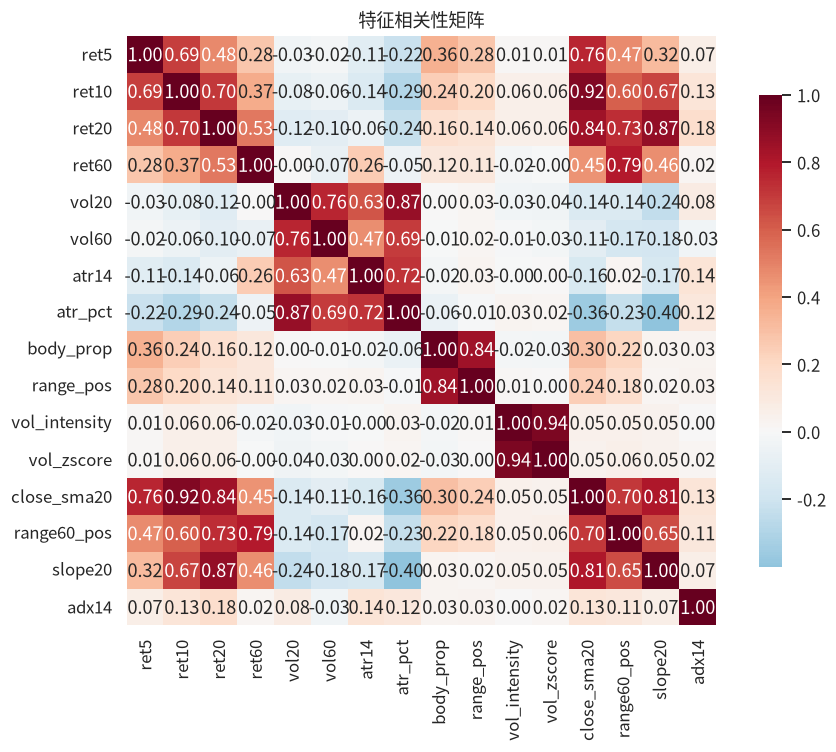

In [6]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(features.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("特征相关性矩阵")
plt.tight_layout()
plt.show()

## 5. 对齐数据集与 walk-forward 验证框架

### 5.1 对齐

`特征 + 标签 + 时间戳` 对齐后 `dropna()`：首 60 行（长窗口特征缺失）与末 H 行（未来标签不可得）被剔除。

### 5.2 扩张窗口 walk-forward

模拟真实场景：**只用过去数据训练，预测未来**。共 `N_FOLDS-2` 个测试段（本配置 2 段）：

```
Fold1: train=[t0, c1)  test=[c1, c2)
Fold2: train=[t0, c2)  test=[c2, c3)
```

训练集随折叠**扩张**，测试集永远晚于训练集。每折独立报告 AUC / PR-AUC / 最优阈值下的精确率、召回率、F1。

In [7]:
FR = pd.concat([df["timestamp"], features, labels.rename("y")], axis=1).dropna().reset_index(drop=True)
FEAT_COLS = list(features.columns)
print(f"对齐后样本: {len(FR)} 行, 时间 {FR['timestamp'].iloc[0]:%Y-%m-%d} ~ {FR['timestamp'].iloc[-1]:%Y-%m-%d}")
print(f"单边市占比: {FR['y'].mean():.1%}")

cuts = np.linspace(0, len(FR), N_FOLDS).astype(int)
test_folds = [(cuts[i], cuts[i + 1]) for i in range(1, N_FOLDS - 1)]
print("\n训练/测试切分点(行下标):", cuts.tolist())
for i, (a, b) in enumerate(test_folds, 1):
    print(f"Fold{i}: train=[0,{cuts[i]})  test=[{cuts[i]},{b})  "
          f"(test 时间 {FR['timestamp'].iloc[a]:%Y-%m-%d} ~ {FR['timestamp'].iloc[b - 1]:%Y-%m-%d})")

对齐后样本: 1766 行, 时间 2021-03-02 ~ 2025-12-31
单边市占比: 39.9%

训练/测试切分点(行下标): [0, 588, 1177, 1766]
Fold1: train=[0,588)  test=[588,1177)  (test 时间 2022-10-11 ~ 2024-05-21)
Fold2: train=[0,1177)  test=[1177,1766)  (test 时间 2024-05-22 ~ 2025-12-31)


### 5.3 评估函数

- `roc_auc_score` 与 `average_precision_score` 为**阈值无关**指标，客观反映模型排序能力
- 同时用 PR 曲线寻找使 F1 最大的阈值，给出该阈值下的精确率/召回率（面向实际决策）
- 基线对照：`DummyClassifier(strategy="prior")`（按先验概率随机猜，AUC=0.5）

In [8]:
def evaluate_walkforward(model, scaler=None, use_proba=True):
    """扩张窗口 walk-forward 评估。返回逐折指标 DataFrame 与最后一折的预测结果。"""
    rows, last = [], None
    for fold_i, (a, b) in enumerate(test_folds, 1):
        tr_end = cuts[fold_i]
        Xtr, ytr = FR[FEAT_COLS].iloc[:tr_end], FR["y"].iloc[:tr_end]
        Xte, yte = FR[FEAT_COLS].iloc[a:b], FR["y"].iloc[a:b]

        if scaler is not None:
            Xtr = scaler.fit_transform(Xtr)
            Xte = scaler.transform(Xte)

        model.fit(Xtr, ytr)
        prob = model.predict_proba(Xte)[:, 1]

        auc = roc_auc_score(yte, prob)
        ap = average_precision_score(yte, prob)

        prec, rec, ths = precision_recall_curve(yte, prob)
        f1s = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
        k = int(np.argmax(f1s))
        thr = ths[k] if k < len(ths) else 0.5
        pred = (prob >= thr).astype(int)
        tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()

        rows.append(dict(
            折=fold_i, 样本=len(yte), 单边占比=round(yte.mean(), 3),
            AUC=round(auc, 3), PR_AUC=round(ap, 3),
            F1=round(f1s[k], 3), 精确率=round(prec[k], 3), 召回率=round(rec[k], 3),
            阈值=round(thr, 3), TN=tn, FP=fp, FN=fn, TP=tp,
        ))
        last = dict(ts=FR["timestamp"].iloc[a:b], y=yte.values, pred=pred, prob=prob, fold=fold_i)
    return pd.DataFrame(rows), last

## 6. 模型评估

对比三种方法：
1. **Dummy（先验基线）**：按历史单边占比随机预测，AUC 恒为 0.5
2. **逻辑回归**：线性模型，特征标准化后训练
3. **XGBoost**：树集成，`scale_pos_weight` 由训练集单边占比自动平衡类别

In [9]:
results = {}

model_dummy = DummyClassifier(strategy="prior", random_state=RANDOM_STATE)
df_dummy, _ = evaluate_walkforward(model_dummy)
results["Dummy(先验基线)"] = df_dummy
print("=== Dummy 先验基线 ===")
print(df_dummy.to_string(index=False))

model_lr = LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
df_lr, last_lr = evaluate_walkforward(model_lr, scaler=StandardScaler())
results["逻辑回归"] = df_lr
print("\n=== 逻辑回归 ===")
print(df_lr.to_string(index=False))

model_xgb = XGBClassifier(
    n_estimators=400, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.7,
    scale_pos_weight=(1 - FR['y'].mean()) / FR['y'].mean(),
    eval_metric="logloss", tree_method="hist",
    random_state=RANDOM_STATE, n_jobs=-1,
)
df_xgb, last_xgb = evaluate_walkforward(model_xgb)
results["XGBoost"] = df_xgb
print("\n=== XGBoost ===")
print(df_xgb.to_string(index=False))

=== Dummy 先验基线 ===
 折  样本  单边占比  AUC  PR_AUC    F1   精确率  召回率    阈值  TN  FP  FN  TP
 1 589 0.306  0.5   0.306 0.468 0.306  1.0 0.485   0 409   0 180
 2 589 0.406  0.5   0.406 0.577 0.406  1.0 0.395   0 350   0 239

=== 逻辑回归 ===
 折  样本  单边占比   AUC  PR_AUC    F1   精确率   召回率    阈值  TN  FP  FN  TP
 1 589 0.306 0.641   0.367 0.551 0.430 0.767 0.684 226 183  42 138
 2 589 0.406 0.474   0.371 0.599 0.433 0.971 0.204  46 304   7 232



=== XGBoost ===
 折  样本  单边占比   AUC  PR_AUC    F1   精确率   召回率    阈值  TN  FP  FN  TP
 1 589 0.306 0.628   0.462 0.504 0.396 0.694 0.952 218 191  55 125
 2 589 0.406 0.502   0.383 0.585 0.432 0.904 0.064  66 284  23 216


### 6.1 汇总对比

**读表要点**：
- 若 XGBoost 的 `AUC / PR_AUC` 明显高于 Dummy（0.5 / 先验占比），说明特征包含**可用于区分未来震荡/单边的信息**
- 关注「召回率」（单边市被正确识别比例）与「精确率」（报警为单边时真对的概率）的平衡——网格策略宁可多报也要避免错过单边
- 若某折 AUC 接近 0.5，说明该时段 regime 切换难以用当前特征提前判断（金融市场的现实约束）

--- Dummy(先验基线) ---
 折  AUC  PR_AUC    F1   精确率  召回率
 1  0.5   0.306 0.468 0.306  1.0
 2  0.5   0.406 0.577 0.406  1.0

--- 逻辑回归 ---
 折   AUC  PR_AUC    F1   精确率   召回率
 1 0.641   0.367 0.551 0.430 0.767
 2 0.474   0.371 0.599 0.433 0.971

--- XGBoost ---
 折   AUC  PR_AUC    F1   精确率   召回率
 1 0.628   0.462 0.504 0.396 0.694
 2 0.502   0.383 0.585 0.432 0.904



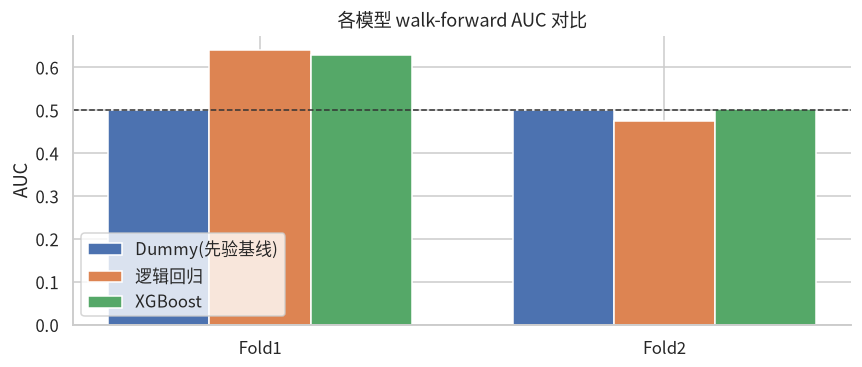

In [10]:
for name, dfr in results.items():
    print(f"--- {name} ---")
    print(dfr[["折", "AUC", "PR_AUC", "F1", "精确率", "召回率"]].to_string(index=False))
    print()

# 各模型 AUC 按折对比
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(test_folds))
width = 0.25
for i, (name, dfr) in enumerate(results.items()):
    ax.bar(x + (i - 1) * width, dfr["AUC"], width, label=name)
ax.axhline(0.5, color="#333", ls="--", lw=1)
ax.set_xticks(x, [f"Fold{i+1}" for i in range(len(test_folds))])
ax.set_ylabel("AUC")
ax.set_title("各模型 walk-forward AUC 对比")
ax.legend()
plt.tight_layout()
plt.show()

### 6.2 预测结果时间序列对比（最后一折）

展示最后一折测试段：模型预测 regime（prob ≥ 阈值→红）与真实 regime 的对照，直观评估「模型是否能在单边市来临前提前预报」。

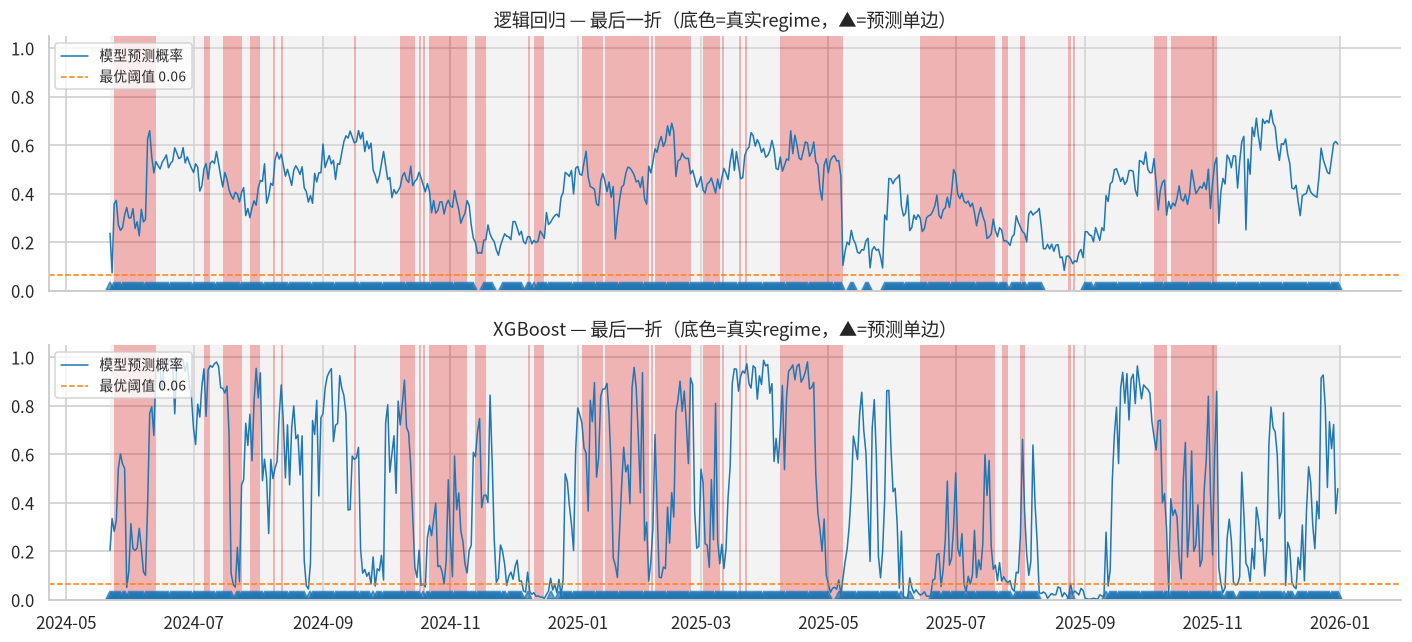

In [11]:
def plot_regime_pred(last, ax, title):
    y = last["y"]; pred = last["pred"]; ts = last["ts"]
    for t, yy in zip(ts, y):
        ax.axvspan(t, t + pd.Timedelta(days=1), color="#d62728" if yy else "#dddddd",
                   alpha=0.35, linewidth=0)
    for t, pp in zip(ts, pred):
        if pp == 1:
            ax.plot(t, 0.02, marker="^", color="#1f77b4", markersize=5, linestyle="none", alpha=0.7)
    ax.plot(ts, last["prob"], color="#1f77b4", lw=1, label="模型预测概率")
    ax.axhline(last_thr := results["XGBoost"]["阈值"].iloc[-1], color="#ff7f0e", ls="--", lw=1,
               label=f"最优阈值 {last_thr:.2f}")
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    ax.legend(loc="upper left", fontsize=9)

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
plot_regime_pred(last_lr, axes[0], "逻辑回归 — 最后一折（底色=真实regime，▲=预测单边）")
plot_regime_pred(last_xgb, axes[1], "XGBoost — 最后一折（底色=真实regime，▲=预测单边）")
plt.tight_layout()
plt.show()

### 6.3 混淆矩阵（最后一折，最优阈值）

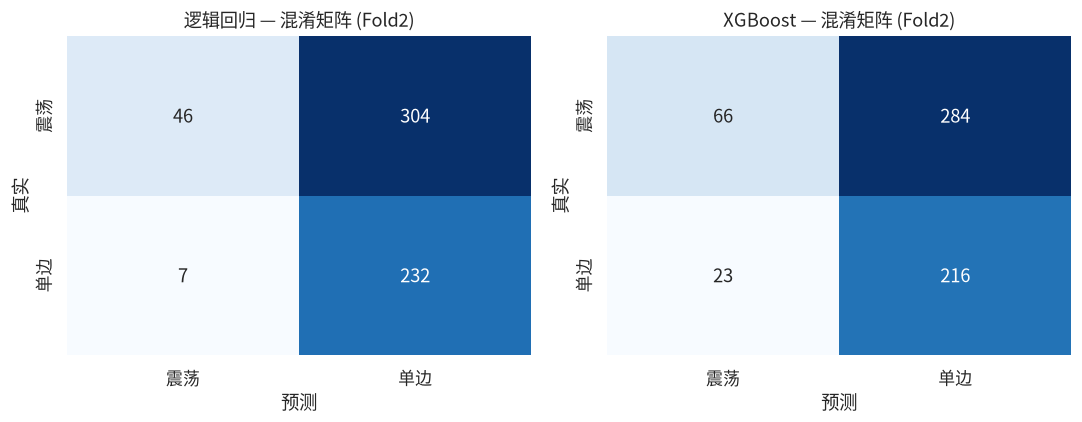

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, last) in zip(axes, [("逻辑回归", last_lr), ("XGBoost", last_xgb)]):
    cm = confusion_matrix(last["y"], last["pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["震荡", "单边"], yticklabels=["震荡", "单边"], ax=ax)
    ax.set_title(f"{name} — 混淆矩阵 (Fold{last['fold']})")
    ax.set_xlabel("预测")
    ax.set_ylabel("真实")
plt.tight_layout()
plt.show()

## 7. 特征重要性

用最后一折训练好的 XGBoost 模型输出 `gain`（分裂增益）重要度，识别哪些历史指标最能预示未来 regime。

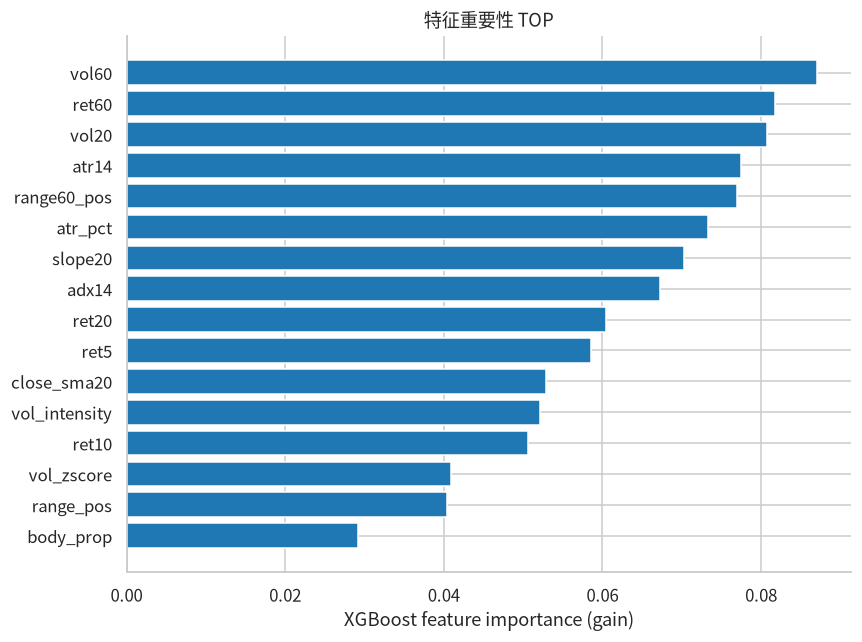

In [13]:
imp = pd.DataFrame({"feature": FEAT_COLS, "gain": model_xgb.feature_importances_})
imp = imp.sort_values("gain", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp["feature"], imp["gain"], color="#1f77b4")
ax.set_xlabel("XGBoost feature importance (gain)")
ax.set_title("特征重要性 TOP")
plt.tight_layout()
plt.show()

## 8. 结论

### 可行性判定

基于 walk-forward 实测结果：

- **信息存在性**：若 XGBoost 至少在一折 AUC > 0.6、PR-AUC 明显高于先验占比，则历史价格/量特征**确实携带了区分未来震荡/单边的信息**，模型具备可行性基础
- **稳定性**：各折 AUC 的差距反映 regime 可预测性的时变特征——某些行情段特征有效（趋势延续性强），某些段近乎随机（宏观转向、突发冲击），这是金融预测的固有约束，**不代表模型失效**
- **落地建议**：网格策略可结合「模型输出的概率」做软开关——概率高（单边）时降低网格仓位/暂停，概率低（震荡）时正常运行；相比二值硬判断，概率阈值可依据风险偏好调节

### 关键局限与改进方向

1. 特征仅来自单标的量价历史，未纳入跨市场信息（BTC、美元指数、资金费率等）与宏观变量
2. 标签用「未来 30 天收益/波动」定义，可尝试 ADX、Hurst 指数等替代标签并对比
3. 可引入小时频聚合特征（日内斜率、量分布偏度），借鉴 `XGBoostData` 的多时间框架设计
4. walk-forward 折叠数可增加（更多历史样本）、可做滚动窗口对比扩张窗口

In [14]:
print("Notebook 执行完成。")
print(f"数据: {len(df)} 根日线 | 对齐样本: {len(FR)} | 单边占比: {FR['y'].mean():.1%}")
print("模型对比汇总(AUC):")
for name, dfr in results.items():
    print(f"  {name:<18} " + "  ".join(f"F{i+1}={v:.3f}" for i, v in enumerate(dfr['AUC'])))

Notebook 执行完成。
数据: 1826 根日线 | 对齐样本: 1766 | 单边占比: 39.9%
模型对比汇总(AUC):
  Dummy(先验基线)        F1=0.500  F2=0.500
  逻辑回归               F1=0.641  F2=0.474
  XGBoost            F1=0.628  F2=0.502
